# ☕ Indian Café Sales 2025: Exploratory Data Analysis

Exploring 1,200 synthetic café orders (in ₹) to answer practical business questions:

1. When does the café make the most money?
2. Which items and categories drive revenue?
3. How do customers pay, and does it change the bill?
4. How happy are customers?

*Note: the dataset is synthetic, built for learning and practice.*

In [1]:
   import pandas as pd
   import numpy as np
   import matplotlib.pyplot as plt
   import seaborn as sns

   sns.set_theme(style='whitegrid')
   plt.rcParams['figure.figsize'] = (10, 5)

   df = pd.read_csv('cafe_sales_2025.csv', parse_dates=['date'])
   df.head()

,order_id,date,hour,day_of_week,item,category,unit_price_inr,quantity,payment_method,dine_in,customer_rating,total_inr
0,ORD100041,2025-01-01,12,Wednesday,Brownie,Dessert,90,1,UPI,No,NaN,90
1,ORD100227,2025-01-02,11,Thursday,Masala Chai,Tea,30,1,Cash,Yes,5.0,30
2,ORD100388,2025-01-02,11,Thursday,Filter Coffee,Coffee,40,1,UPI,No,5.0,40
3,ORD100833,2025-01-02,11,Thursday,Veg Sandwich,Food,110,2,Cash,Yes,3.0,220
4,ORD100816,2025-01-02,15,Thursday,Brownie,Dessert,90,2,UPI,Yes,NaN,180


## 1. Data quality check

In [2]:
print(df.shape)
print(df.dtypes)
print('\nMissing values:')
print(df.isna().sum())
print(f"\nMissing ratings: {df.customer_rating.isna().mean():.1%}")

(1200, 12)
order_id                   object
date               datetime64[ns]
hour                        int64
day_of_week                object
item                       object
category                   object
unit_price_inr              int64
quantity                    int64
payment_method             object
dine_in                    object
customer_rating           float64
total_inr                   int64
dtype: object

Missing values:
order_id             0
date                 0
hour                 0
day_of_week          0
item                 0
category             0
unit_price_inr       0
quantity             0
payment_method       0
dine_in              0
customer_rating    233
total_inr            0
dtype: int64

Missing ratings: 19.4%


Only `customer_rating` has missing values (about 19%), which is realistic since many customers skip rating. I'll leave them out of rating averages rather than filling them in.

In [3]:
print(f"Total orders : {len(df):,}")
print(f"Total revenue: ₹{df.total_inr.sum():,}")
print(f"Average bill : ₹{df.total_inr.mean():.1f}")

Total orders : 1,200
Total revenue: ₹149,140
Average bill : ₹124.3


## 2. When does the café earn the most?

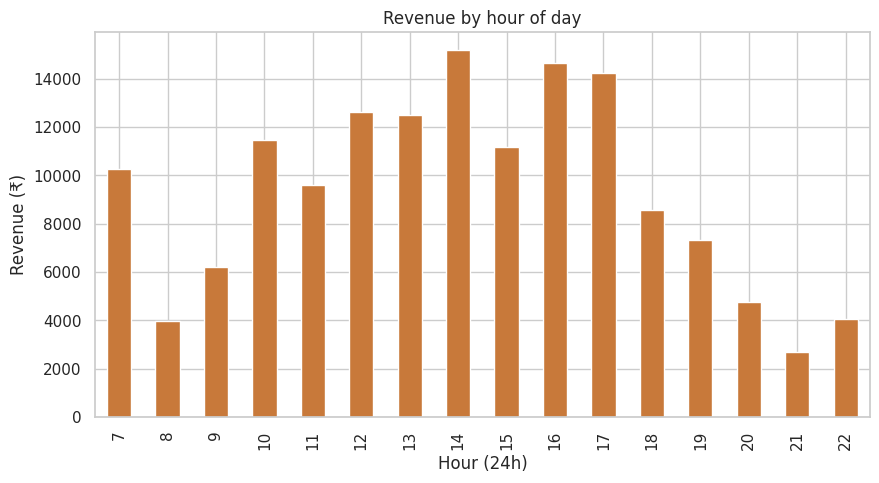

In [4]:
hourly = df.groupby('hour').total_inr.sum()
ax = hourly.plot(kind='bar', color='#c8793a')
ax.set_title('Revenue by hour of day')
ax.set_xlabel('Hour (24h)')
ax.set_ylabel('Revenue (₹)')
plt.show()

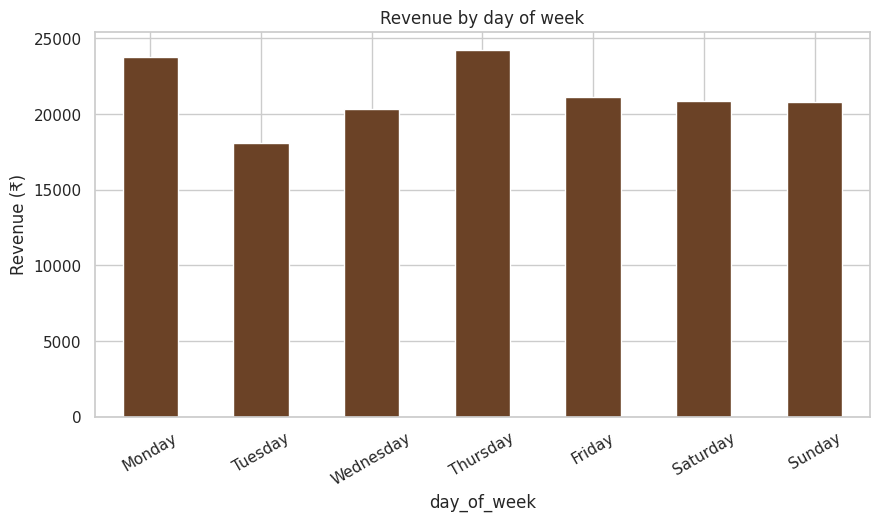

In [5]:
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
daily = df.groupby('day_of_week').total_inr.sum().reindex(order)
ax = daily.plot(kind='bar', color='#6b4226')
ax.set_title('Revenue by day of week')
ax.set_ylabel('Revenue (₹)')
plt.xticks(rotation=30)
plt.show()

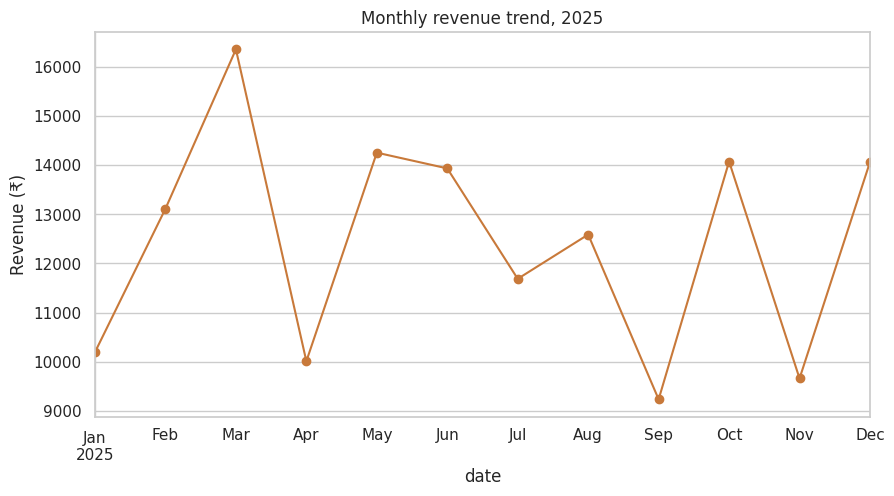

In [6]:
monthly = df.groupby(df.date.dt.to_period('M')).total_inr.sum()
ax = monthly.plot(marker='o', color='#c8793a')
ax.set_title('Monthly revenue trend, 2025')
ax.set_ylabel('Revenue (₹)')
plt.show()

**Takeaway:** the afternoon is the money zone, with the busiest revenue hours around 12 PM to 5 PM. Staffing and prep should peak then, not in the morning.

## 3. What sells?

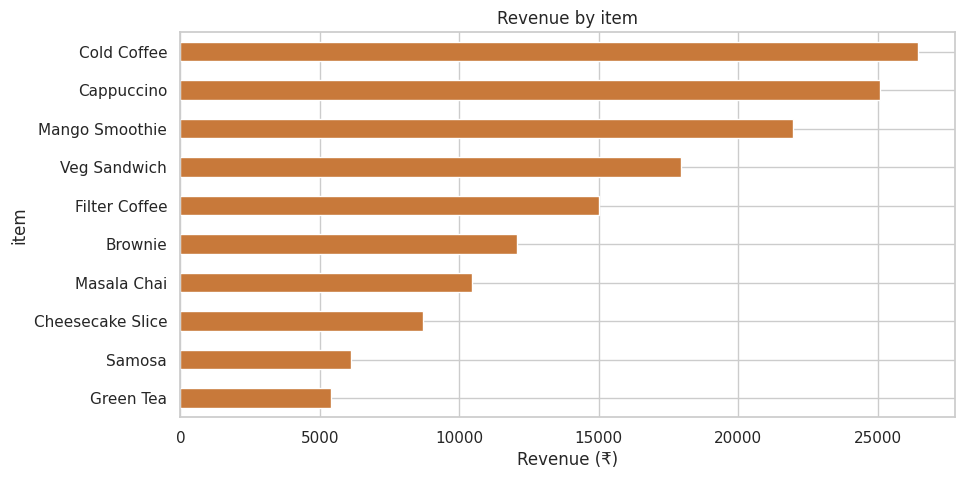

In [7]:
top_items = df.groupby('item').total_inr.sum().sort_values()
ax = top_items.plot(kind='barh', color='#c8793a')
ax.set_title('Revenue by item')
ax.set_xlabel('Revenue (₹)')
plt.show()

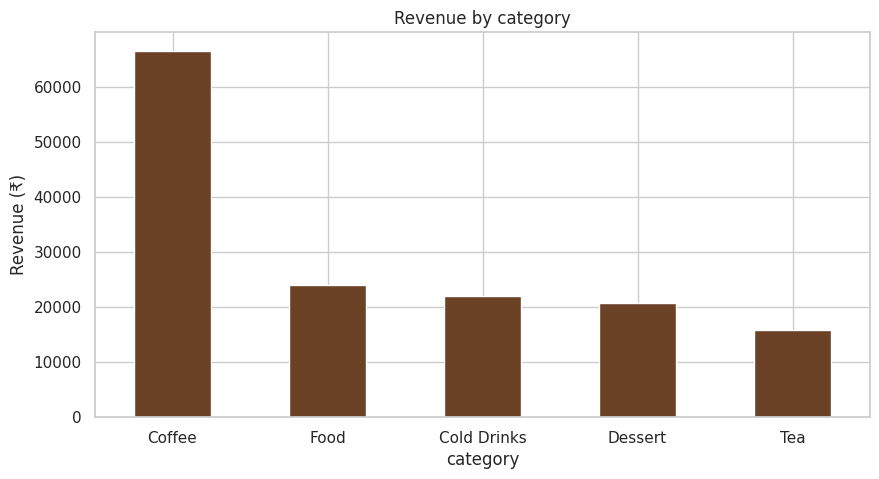

category
Coffee         44.6%
Food           16.1%
Cold Drinks    14.7%
Dessert        13.9%
Tea            10.6%
Name: total_inr, dtype: object


In [8]:
cat = df.groupby('category').total_inr.sum().sort_values(ascending=False)
ax = cat.plot(kind='bar', color='#6b4226')
ax.set_title('Revenue by category')
ax.set_ylabel('Revenue (₹)')
plt.xticks(rotation=0)
plt.show()

print((cat / cat.sum() * 100).round(1).astype(str) + '%')

**Takeaway:** Coffee is the engine, bringing in over 40% of revenue. Cheap, high-volume items like Masala Chai and Samosa sell often but earn little, while Cold Coffee and Cappuccino lead on revenue.

## 4. Payments

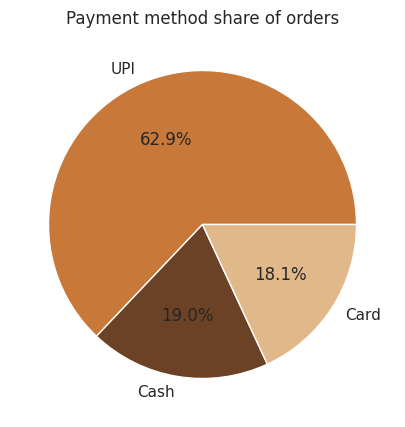

In [9]:
pay = df.payment_method.value_counts()
ax = pay.plot(kind='pie', autopct='%1.1f%%', colors=['#c8793a','#6b4226','#e0b88a'], ylabel='')
ax.set_title('Payment method share of orders')
plt.show()

payment_method
Card    133.2
Cash    116.2
UPI     124.1
Name: total_inr, dtype: float64


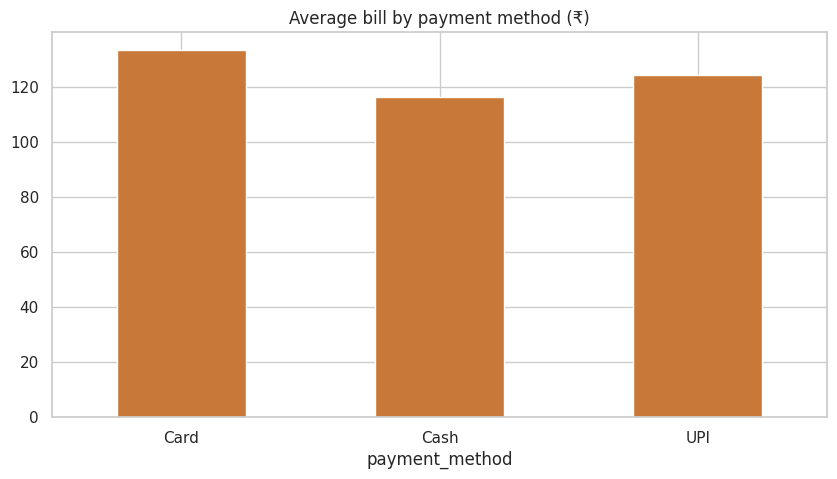

In [10]:
avg_bill = df.groupby('payment_method').total_inr.mean().round(1)
print(avg_bill)
ax = avg_bill.plot(kind='bar', color='#c8793a')
ax.set_title('Average bill by payment method (₹)')
plt.xticks(rotation=0)
plt.show()

**Takeaway:** UPI is used in about 63% of orders, and card payers spend slightly more per order than cash payers.

## 5. Customer satisfaction

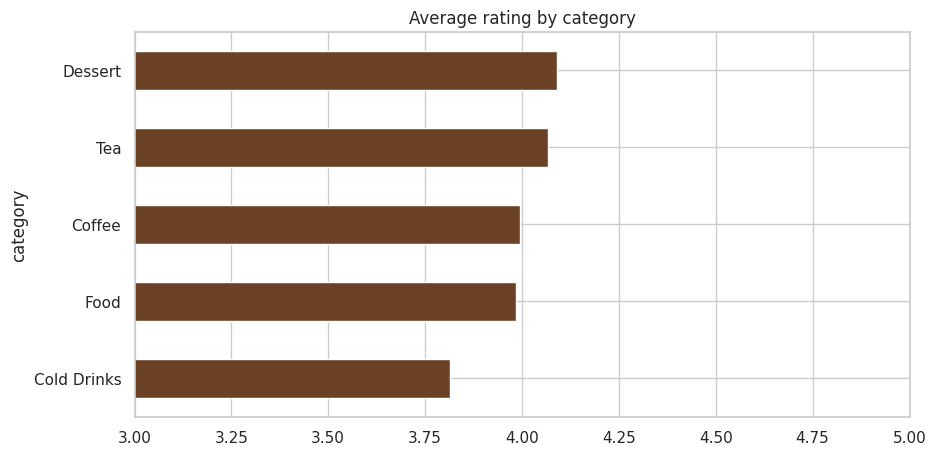

In [11]:
rating = df.groupby('category').customer_rating.mean().sort_values()
ax = rating.plot(kind='barh', color='#6b4226')
ax.set_title('Average rating by category')
ax.set_xlim(3, 5)
plt.show()

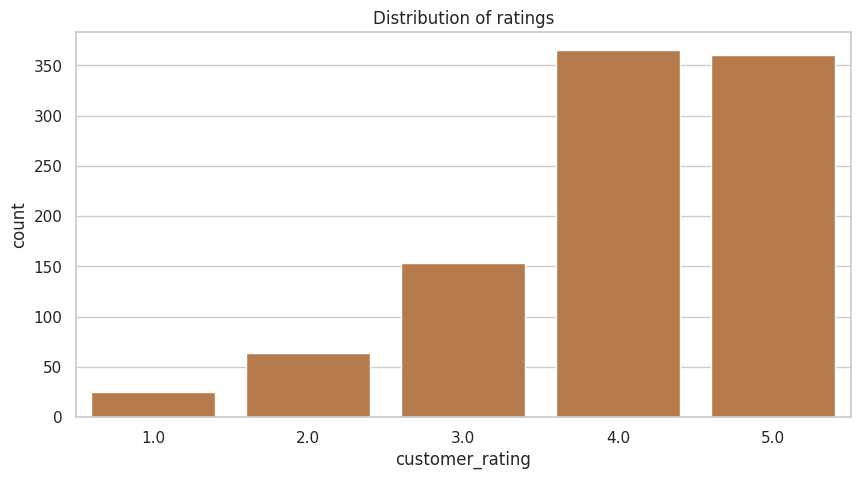

In [12]:
sns.countplot(data=df, x='customer_rating', color='#c8793a')
plt.title('Distribution of ratings')
plt.show()

**Takeaway:** ratings are healthy across the board (about 3.8 to 4.1). Desserts score highest and Cold Drinks lowest, but the gaps are small.

## 6. Dine-in vs takeaway

In [13]:
print(df.groupby('dine_in').agg(orders=('order_id','count'), avg_bill=('total_inr','mean')).round(1))

         orders  avg_bill
dine_in                  
No          419     121.9
Yes         781     125.6


## Summary

- Afternoons (12 PM to 5 PM) are the peak revenue window.
- Coffee drives about 45% of revenue, led by Cold Coffee and Cappuccino.
- UPI dominates payments at about 63% of orders.
- Dine-in customers spend only slightly more than takeaway customers.
- Ratings are consistently good, with Desserts on top.

**Next steps:** forecast daily revenue, or predict customer rating from order features.

If you found this useful, please upvote 🙌